In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("customer_data.csv")


In [46]:
df.head()

,Customer_Name,Last_Purchase_Date,Total_Spend,Region
0,Aarav Sharma,2026-08-01,2500,West
1,Priya Patil,2026-07-25,4500,West
2,Rahul Kulkarni,2026-08-10,3200,North
3,Sneha Joshi,2026-07-15,1800,West
4,Amit Deshmukh,2026-08-05,5200,East


In [12]:
df.tail()

,Customer_Name,Last_Purchase_Date,Total_Spend,Region
45,Poonam Mishra,2026-08-08,5400,South
46,Amol Thakur,2026-07-17,3350,West
47,Rashmi Kapoor,2026-08-15,6700,North
48,Vishal Malhotra,2026-07-31,4150,West
49,Mrunal Kaur,2026-08-06,3050,South


In [48]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 50
Columns: 4


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer_Name       50 non-null     object
 1   Last_Purchase_Date  50 non-null     object
 2   Total_Spend         50 non-null     int64 
 3   Region              50 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.7+ KB


In [55]:
df.dtypes

Customer_Name         object
Last_Purchase_Date    object
Total_Spend            int64
Region                object
dtype: object

In [57]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numerical_cols)

print("Categorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['Total_Spend'], dtype='object')
Categorical Columns:
Index(['Customer_Name', 'Last_Purchase_Date', 'Region'], dtype='object')


In [59]:
df["Last_Purchase_Date"] = pd.to_datetime(
    df["Last_Purchase_Date"]
)

df.dtypes

Customer_Name                 object
Last_Purchase_Date    datetime64[ns]
Total_Spend                    int64
Region                        object
dtype: object

In [61]:
df.describe()

,Last_Purchase_Date,Total_Spend
count,50,50.000000
mean,2026-07-26 18:43:12,4170.000000
min,2026-06-20 00:00:00,1800.000000
25%,2026-07-18 06:00:00,2975.000000
50%,2026-07-30 12:00:00,4000.000000
75%,2026-08-07 18:00:00,5275.000000
max,2026-08-16 00:00:00,7200.000000
std,NaN,1495.128143


In [63]:
print("Average Spending:", df["Total_Spend"].mean())

print("Maximum Spending:", df["Total_Spend"].max())

print("Minimum Spending:", df["Total_Spend"].min())

print("Median Spending:", df["Total_Spend"].median())

Average Spending: 4170.0
Maximum Spending: 7200
Minimum Spending: 1800
Median Spending: 4000.0


In [65]:
df.isnull().sum()

Customer_Name         0
Last_Purchase_Date    0
Total_Spend           0
Region                0
dtype: int64

In [67]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Customer_Name         0.0
Last_Purchase_Date    0.0
Total_Spend           0.0
Region                0.0
dtype: float64


In [69]:
clean_df = df.copy()

In [71]:
clean_df["Total_Spend"] = clean_df["Total_Spend"].fillna(
    clean_df["Total_Spend"].median()
)

In [73]:
for col in ["Customer_Name", "Region"]:
    clean_df[col] = clean_df[col].fillna(
        clean_df[col].mode()[0]
    )

In [75]:
clean_df.isnull().sum()

Customer_Name         0
Last_Purchase_Date    0
Total_Spend           0
Region                0
dtype: int64

In [77]:
print("Duplicate Records:", clean_df.duplicated().sum())

Duplicate Records: 0


In [79]:
clean_df = clean_df.drop_duplicates()

In [81]:
clean_df.duplicated().sum()

0

In [83]:
region_count = clean_df["Region"].value_counts()

print(region_count)

Region
West     20
South    12
North    11
East      7
Name: count, dtype: int64


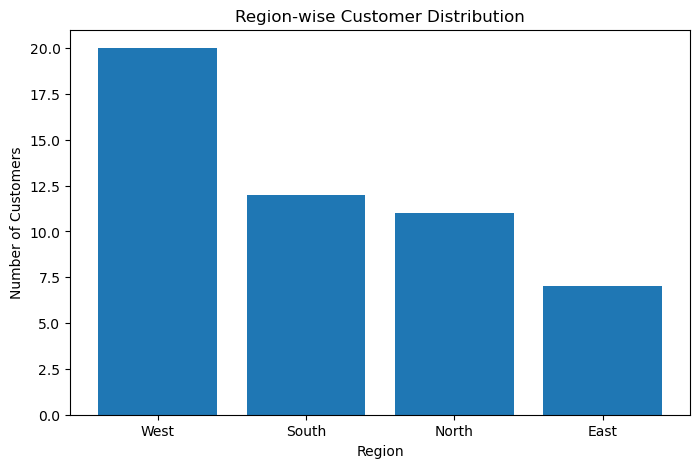

In [85]:
plt.figure(figsize=(8,5))

plt.bar(region_count.index, region_count.values)

plt.title("Region-wise Customer Distribution")
plt.xlabel("Region")
plt.ylabel("Number of Customers")

plt.show()

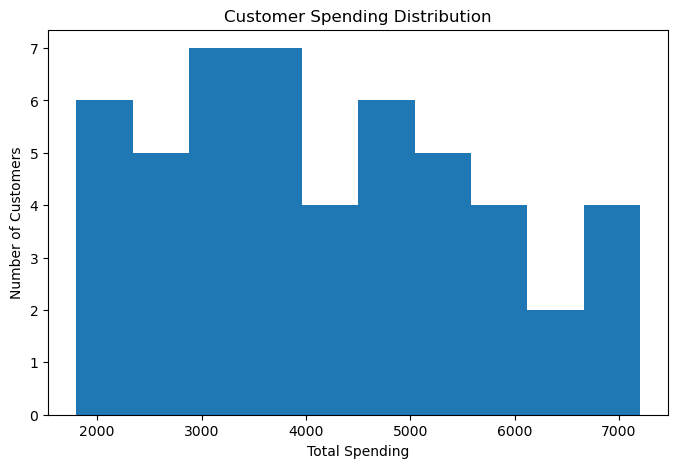

In [87]:
plt.figure(figsize=(8,5))

plt.hist(clean_df["Total_Spend"], bins=10)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.show()

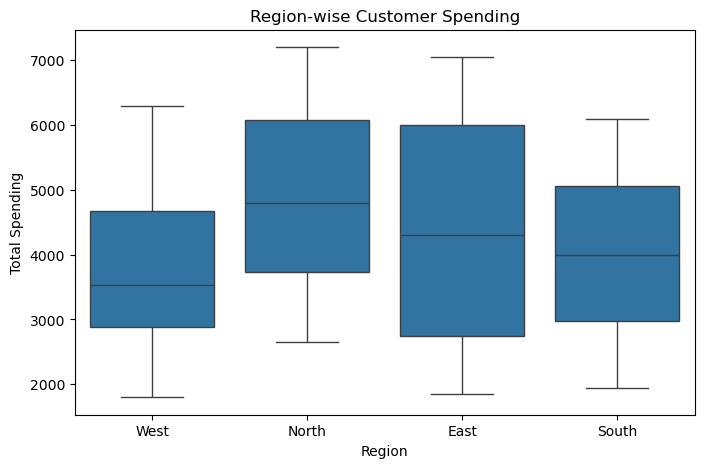

In [89]:
plt.figure(figsize=(8,5))

sns.boxplot(data=clean_df, x="Region", y="Total_Spend")

plt.title("Region-wise Customer Spending")
plt.xlabel("Region")
plt.ylabel("Total Spending")

plt.show()

In [91]:
avg_spending = clean_df.groupby("Region")["Total_Spend"].mean()

print(avg_spending)

Region
East     4385.714286
North    4877.272727
South    4041.666667
West     3782.500000
Name: Total_Spend, dtype: float64


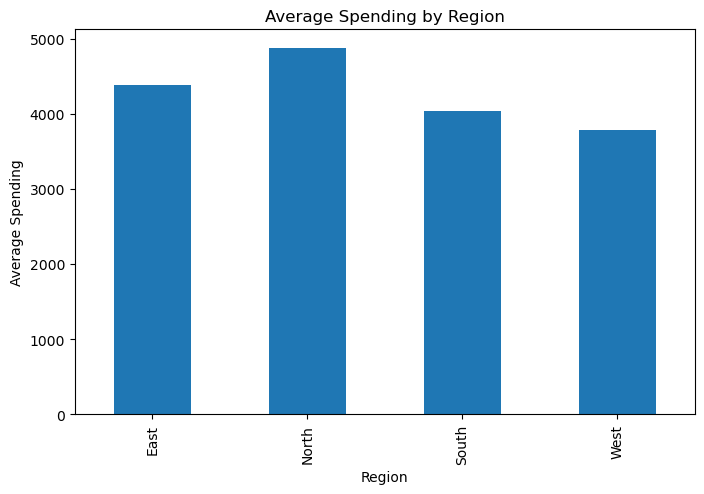

In [93]:
avg_spending.plot(kind="bar", figsize=(8,5))

plt.title("Average Spending by Region")
plt.xlabel("Region")
plt.ylabel("Average Spending")

plt.show()

In [95]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["Region"],
    dtype=int
)

encoded_df.head()

,Customer_Name,Last_Purchase_Date,Total_Spend,Region_East,Region_North,Region_South,Region_West
0,Aarav Sharma,2026-08-01,2500,0,0,0,1
1,Priya Patil,2026-07-25,4500,0,0,0,1
2,Rahul Kulkarni,2026-08-10,3200,0,1,0,0
3,Sneha Joshi,2026-07-15,1800,0,0,0,1
4,Amit Deshmukh,2026-08-05,5200,1,0,0,0


In [97]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

encoded_df["Total_Spend_Scaled"] = scaler.fit_transform(
    encoded_df[["Total_Spend"]]
)

encoded_df.head()

,Customer_Name,Last_Purchase_Date,Total_Spend,Region_East,Region_North,Region_South,Region_West,Total_Spend_Scaled
0,Aarav Sharma,2026-08-01,2500,0,0,0,1,-1.128301
1,Priya Patil,2026-07-25,4500,0,0,0,1,0.222958
2,Rahul Kulkarni,2026-08-10,3200,0,1,0,0,-0.655361
3,Sneha Joshi,2026-07-15,1800,0,0,0,1,-1.601242
4,Amit Deshmukh,2026-08-05,5200,1,0,0,0,0.695898


In [99]:
encoded_df.to_csv(
    "prepared_customer_data.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [101]:
print("Final Shape:", encoded_df.shape)

print("Missing Values:", encoded_df.isnull().sum().sum())

print("Duplicates:", encoded_df.duplicated().sum())

Final Shape: (50, 8)
Missing Values: 0
Duplicates: 0
